In [1]:
import random
import numpy as np
import matplotlib.pyplot as plt

In [2]:
tasks = {
    "Persiapan": (1, 2, 3),
    "Pondasi": (2, 3, 5),
    "Struktur": (4, 6, 9),
    "Instalasi": (3, 5, 7),
    "Finishing": (2, 4, 6)
}

In [3]:
def pert_time(a, m, b):
    return (a + 4*m + b) / 6

def total_duration(tasks):
    return sum(pert_time(a, m, b) for a, m, b in tasks.values())

print("Estimasi waktu:", total_duration(tasks))

Estimasi waktu: 20.333333333333332


In [4]:
def monte_carlo(tasks, n=5000):
    results = []

    for _ in range(n):
        total = 0
        for a, m, b in tasks.values():
            duration = random.triangular(a, b, m)

            delay = random.choice([0, 0.1, 0.2])
            duration *= (1 + delay)

            total += duration

        results.append(total)

    return results

results = monte_carlo(tasks)

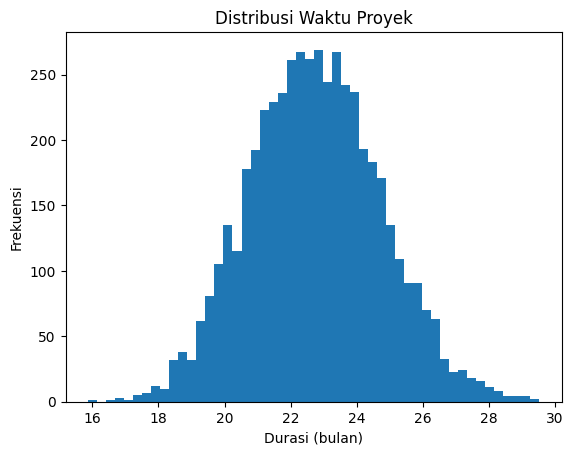

In [5]:
plt.hist(results, bins=50)
plt.title("Distribusi Waktu Proyek")
plt.xlabel("Durasi (bulan)")
plt.ylabel("Frekuensi")
plt.show()

In [6]:
def probability(results, deadline):
    return sum(r <= deadline for r in results) / len(results)

for d in [16, 20, 24]:
    print(f"Deadline {d}: {probability(results, d)*100:.2f}%")

Deadline 16: 0.02%
Deadline 20: 8.20%
Deadline 24: 73.84%


In [7]:
def add_resources(tasks, factor=0.8):
    return {k: (a*factor, m*factor, b*factor) for k, (a,m,b) in tasks.items()}

new_tasks = add_resources(tasks)
new_results = monte_carlo(new_tasks)

print("Durasi baru:", total_duration(new_tasks))

for d in [16, 20, 24]:
    print(f"(Resource) Deadline {d}: {probability(new_results, d)*100:.2f}%")

Durasi baru: 16.266666666666666
(Resource) Deadline 16: 9.42%
(Resource) Deadline 20: 86.16%
(Resource) Deadline 24: 99.98%
